# Data Cleaning and Exploratory Data Analysis (EDA)

## 1. Introduction

The goal of this project is to practice data inspection, data cleaning, and exploratory data analysis using Python.

The Iris dataset is used to explore flower measurements, inspect data quality, and identify relationships between numerical features.

### Objectives

- Inspect the dataset structure and data types.
- Identify missing values and duplicate records.
- Clean the dataset where necessary.
- Create at least four visualizations.
- Document the main findings and data quality issues.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)

df = iris.frame

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [4]:
df.shape


(150, 5)

In [5]:
df.columns


Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'target'],
      dtype='object')

In [7]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [8]:
df.isnull().sum()


,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
target,0


In [9]:
df.duplicated().sum()

np.int64(1)

In [10]:
df[df.duplicated(keep=False)]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
101,5.8,2.7,5.1,1.9,2
142,5.8,2.7,5.1,1.9,2


In [14]:
df_clean = df.drop_duplicates().copy()

print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)
print("Duplicates after cleaning:", df_clean.duplicated().sum())

Original dataset: (150, 5)
Cleaned dataset: (149, 5)
Duplicates after cleaning: 0


In [15]:
df_clean.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,149.000000,149.000000,149.000000,149.000000,149.000000
mean,5.843624,3.059732,3.748993,1.194631,0.993289
std,0.830851,0.436342,1.767791,0.762622,0.817847
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.300000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


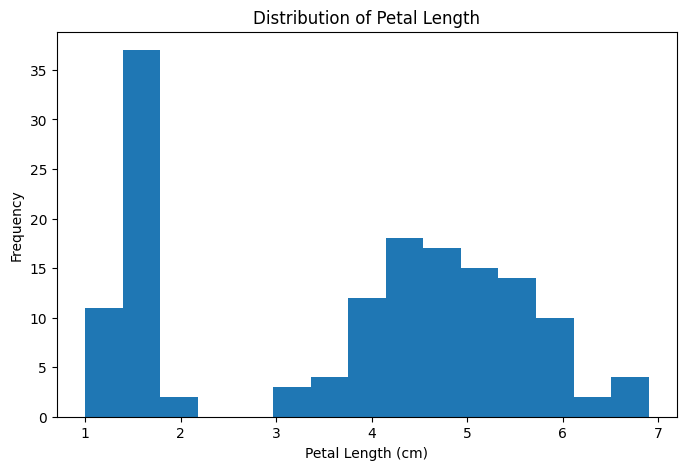

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df_clean["petal length (cm)"], bins=15)

plt.title("Distribution of Petal Length")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Frequency")

plt.show()

### EDA – Histogram of Petal Length

The histogram shows that petal lengths are distributed across distinct ranges. A large concentration of observations appears around 1–2 cm, while another concentration appears around 4–6 cm. There are relatively few observations between approximately 2 and 3 cm.

This pattern suggests that the dataset may contain distinct groups of flowers with different petal lengths. Further analysis using flower categories can help explain this distribution.

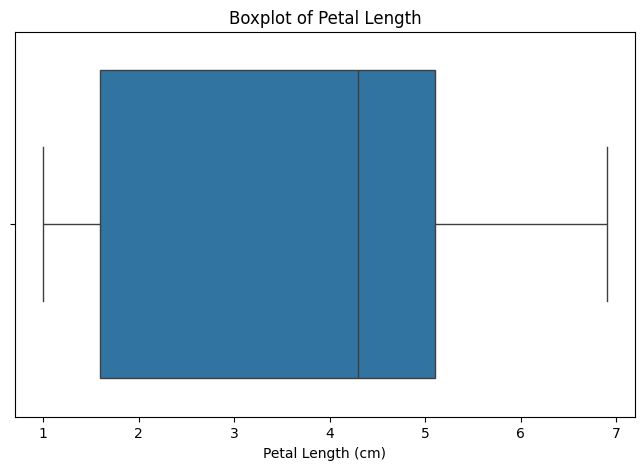

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

sns.boxplot(x=df_clean["petal length (cm)"])

plt.title("Boxplot of Petal Length")
plt.xlabel("Petal Length (cm)")

plt.show()

### EDA – Boxplot of Petal Length

The boxplot shows that petal lengths range from approximately 1.0 cm to 6.9 cm. The median is approximately 4.3 cm. No potential outliers are visibly identified by the boxplot rule.

This suggests that no observations were flagged as outliers for petal length using this method. However, the absence of flagged outliers does not guarantee that all data values are error-free.

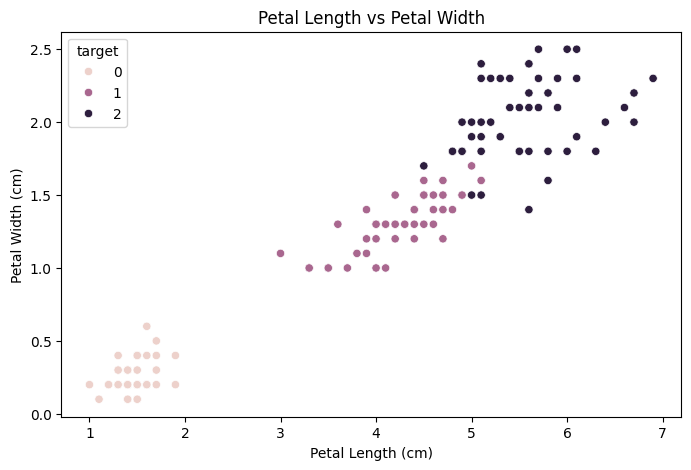

In [18]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="target"
)

plt.title("Petal Length vs Petal Width")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")

plt.show()

### EDA – Petal Length vs Petal Width

The scatter plot shows a positive relationship between petal length and petal width. Flowers with longer petals generally tend to have wider petals.

The three target classes form distinct groups, particularly class 0, which appears in the lower-left region of the plot. Classes 1 and 2 occupy regions with larger petal measurements.

These patterns suggest that petal measurements help distinguish the flower classes.

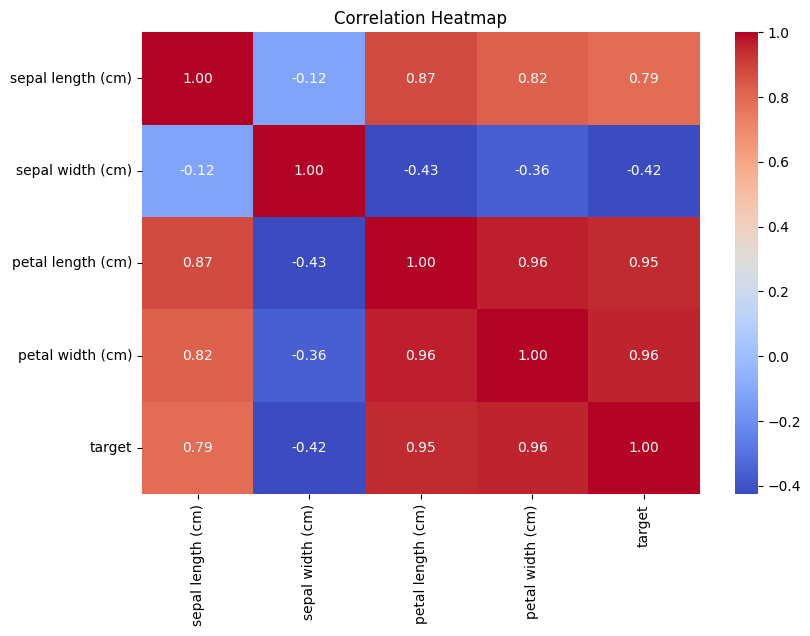

In [19]:
plt.figure(figsize=(9, 6))

correlation = df_clean.corr(
    numeric_only=True
)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

### EDA – Correlation Heatmap

The correlation heatmap reveals a strong positive linear relationship between petal length and petal width (r = 0.96). Sepal length is also positively correlated with petal length (r = 0.87) and petal width (r = 0.82).

Sepal width shows negative correlations with petal length (r = -0.43) and petal width (r = -0.36).

These results indicate that petal measurements tend to increase together. Correlation does not imply causation. The `target` column represents encoded flower classes, so its correlation values should be interpreted cautiously.

## 5. Conclusion

This project provided practical experience in inspecting, cleaning, and exploring a real dataset using Python.

The analysis identified one fully duplicated record, which was removed from the working dataset. No missing values were detected.

The visualizations revealed a strong positive relationship between petal length and petal width, as well as visible differences between the encoded flower classes.

This project demonstrates the importance of checking data quality and understanding the data before applying machine learning models.